# Improving RAG with Reranking, Chunking, and Conversational Memory
**DATA 266 — Ritika Mukesh Neema**

**Dataset:** `ccdv/arxiv-summarization`, `document` subset, first 100 papers of the train split.
**Stack:** `all-MiniLM-L6-v2` bi-encoder · ChromaDB (cosine HNSW) · `ms-marco-MiniLM-L-6-v2` cross-encoder reranker · history-aware query rewriting for memory.

| Section | What it does |
|---|---|
| 1 | Setup and configuration |
| 2 | Load + preprocess (remove `@xmath`/`@xcite` placeholders, fix tokenized punctuation, sentence split) |
| 3 | Two chunking strategies: **S1 fixed word window** vs **S2 sentence-aware packing** |
| 4 | Embed and index both strategies in ChromaDB |
| 5 | Retrieval without and with reranking |
| 6 | Queries + manually defined relevance |
| 7 | Sample queries: no-rerank vs rerank |
| 8 | Conversational memory + multi-turn demo |
| 9 | Evaluation: Precision@K, Recall@K, MRR |
| 10 | Comparisons, charts, findings |

Runtime: Colab T4 GPU (CPU also works, just slower). Every stage ends with a verification check.

## 1. Setup

In [1]:
!pip -q install -U datasets sentence-transformers chromadb

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 4.0.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 4.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 4.0.0 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2

In [2]:
import re, json, random, time, warnings
from collections import defaultdict
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 6638
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

N_DOCS        = 100
EMBED_MODEL   = "sentence-transformers/all-MiniLM-L6-v2"   # max 256 word-pieces
RERANK_MODEL  = "cross-encoder/ms-marco-MiniLM-L-6-v2"
CHUNK_WORDS   = 120    # ~1.55 word-pieces/word on this data -> stays under MiniLM's 256 limit
OVERLAP_WORDS = 24     # S1 overlap (20%)
OVERLAP_SENTS = 1      # S2 overlap (1 sentence)
CANDIDATES    = 20     # first-stage pool that the reranker rescores
KS            = [3, 5, 10]
K_MAIN        = 5
pd.set_option("display.max_colwidth", 120)
print("device:", DEVICE)

device: cuda


## 2. Load and preprocess

In [3]:
from datasets import load_dataset

def load_docs(n=N_DOCS):
    try:
        return load_dataset("ccdv/arxiv-summarization", "document", split=f"train[:{n}]")
    except Exception as e:                       # fallback if split slicing / builder fails
        print(f"Direct load failed ({type(e).__name__}); streaming first {n} rows instead.")
        stream = load_dataset("ccdv/arxiv-summarization", "document", split="train", streaming=True)
        from datasets import Dataset
        return Dataset.from_list(list(stream.take(n)))

raw = load_docs()
print(raw)
assert len(raw) == N_DOCS and {"article", "abstract"} <= set(raw.column_names)
print("\nRaw article sample:\n", raw[0]["article"][:400])

README.md:   0%|          | 0.00/3.96k [00:00<?, ?B/s]

document/train-00000-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  227MB            

document/train-00000-of-00015.parquet: downloading bytes:           |  0.00B            

document/train-00001-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  226MB            

document/train-00001-of-00015.parquet: downloading bytes:           |  0.00B            

document/train-00002-of-00015.parquet: reconstructing file:   0%|          |  0.00B /  226MB            

... (29 outputs left out)

Generating train split:   0%|          | 0/203037 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/6436 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/6440 [00:00<?, ? examples/s]

Dataset({
    features: ['article', 'abstract'],
    num_rows: 100
})

Raw article sample:
 additive models @xcite provide an important family of models for semiparametric regression or classification . some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models . it is well - known that good estimators in additive models are in general


In [4]:
MATH_RE = re.compile(r"@xmath\d*")
CITE_RE = re.compile(r"@xcite\d*")

def clean_text(t: str) -> str:
    t = MATH_RE.sub(" ", t)                              # equations were replaced by @xmathN
    t = CITE_RE.sub(" ", t)                              # citations were replaced by @xciteN
    t = re.sub(r"(\w) - (\w)", r"\1-\2", t)              # "mid - infrared" -> "mid-infrared"
    t = re.sub(r"\s+([.,;:!?)\]])", r"\1", t)            # "word ." -> "word."
    t = re.sub(r"([(\[])\s+", r"\1", t)                  # "( word" -> "(word"
    t = re.sub(r"[(\[]\s*[,;.]*\s*[)\]]", " ", t)       # empty brackets left behind
    t = re.sub(r"([,;])(\s*[,;])+", r"\1", t)            # ", ," -> ","
    t = re.sub(r"\s+", " ", t).strip()
    return t

def split_sentences(article: str):
    lines = [l for l in article.split("\n") if l.strip()]
    if len(lines) <= 1:                                  # no newline sentence markers
        lines = re.split(r"(?<=[.!?])\s+", article)
    sents = [clean_text(l) for l in lines]
    return [s for s in sents if len(s.split()) >= 4]     # drop fragments left by math removal

docs = []
for i, row in enumerate(raw):
    sents = split_sentences(row["article"])
    docs.append({"doc_id": i, "sentences": sents, "text": " ".join(sents),
                 "abstract": clean_text(row["abstract"].replace("\n", " "))})

lens = np.array([len(d["text"].split()) for d in docs])
print(f"docs: {len(docs)} | words/doc mean {lens.mean():.0f}, min {lens.min()}, max {lens.max()}")
print("placeholders left:", sum(bool(MATH_RE.search(d["text"]) or CITE_RE.search(d["text"])) for d in docs))
print("\nClean sample:\n", docs[0]["text"][:400])
assert all(len(d["sentences"]) > 0 for d in docs)

docs: 100 | words/doc mean 4937, min 446, max 24354
placeholders left: 0

Clean sample:
 additive models provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonparametric models. it is well-known that good estimators in additive models are in general less prone


## 3. Two chunking strategies
* **S1 — fixed word window:** 120 words, 24-word overlap. Simple, uniform size, but cuts mid-sentence.
* **S2 — sentence-aware packing:** whole sentences packed up to 120 words, 1-sentence overlap. Chunks end on sentence boundaries; overlong sentences are hard-split.

Both use the same 120-word budget so the comparison isolates *boundary placement*, not chunk length.

In [5]:
def fixed_window_chunks(text, size=CHUNK_WORDS, overlap=OVERLAP_WORDS):
    w = text.split()
    if len(w) <= size:
        return [" ".join(w)]
    step = size - overlap
    starts = list(range(0, len(w) - size + 1, step))
    if starts[-1] + size < len(w):
        starts.append(len(w) - size)                     # last window aligned to the end
    return [" ".join(w[s:s + size]) for s in starts]

def sentence_chunks(sentences, max_words=CHUNK_WORDS, overlap_sents=OVERLAP_SENTS):
    units = []
    for s in sentences:                                   # hard-split sentences longer than the budget
        ws = s.split()
        units += [" ".join(ws[i:i + max_words]) for i in range(0, len(ws), max_words)] if len(ws) > max_words else [s]
    chunks, cur, cur_len = [], [], 0
    for u in units:
        n = len(u.split())
        if cur and cur_len + n > max_words:
            chunks.append(" ".join(cur))
            cur = cur[-overlap_sents:] if overlap_sents else []
            cur_len = sum(len(x.split()) for x in cur)
            if cur_len + n > max_words:
                cur, cur_len = [], 0
        cur.append(u); cur_len += n
    if cur:
        chunks.append(" ".join(cur))
    return chunks

def build_chunks(strategy):
    out = []
    for d in docs:
        pieces = fixed_window_chunks(d["text"]) if strategy == "S1" else sentence_chunks(d["sentences"])
        for j, p in enumerate(pieces):
            out.append({"id": f"{strategy}-d{d['doc_id']}-c{j}", "text": p,
                        "doc_id": d["doc_id"], "chunk_idx": j, "strategy": strategy})
    return out

CHUNKS = {s: build_chunks(s) for s in ["S1", "S2"]}
STRATEGY_NAMES = {"S1": "S1 fixed window", "S2": "S2 sentence-aware"}

stats = []
for s, ch in CHUNKS.items():
    L = np.array([len(c["text"].split()) for c in ch])
    ends_clean = np.mean([c["text"].rstrip()[-1:] in ".!?" for c in ch])
    stats.append({"strategy": STRATEGY_NAMES[s], "chunks": len(ch), "mean_words": round(L.mean(), 1),
                  "min_words": L.min(), "max_words": L.max(), "ends_on_sentence": f"{ends_clean:.0%}"})
display(pd.DataFrame(stats))
for s in CHUNKS:
    print(f"\n{STRATEGY_NAMES[s]} — first chunk of doc 0:\n", CHUNKS[s][0]["text"][:300], "...")
assert all(len(c["text"].split()) <= CHUNK_WORDS for ch in CHUNKS.values() for c in ch)

,strategy,chunks,mean_words,min_words,max_words,ends_on_sentence
0,S1 fixed window,5164,120.0,120,120,7%
1,S2 sentence-aware,5723,106.3,8,120,98%



S1 fixed window — first chunk of doc 0:
 additive models provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonp ...

S2 sentence-aware — first chunk of doc 0:
 additive models provide an important family of models for semiparametric regression or classification. some reasons for the success of additive models are their increased flexibility when compared to linear or generalized linear models and their increased interpretability when compared to fully nonp ...


## 4. Embed and index in ChromaDB

In [6]:
from sentence_transformers import SentenceTransformer, CrossEncoder
import chromadb

embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
reranker = CrossEncoder(RERANK_MODEL, device=DEVICE, max_length=512)

# Verification: how many chunks exceed the embedder's input limit (would be silently truncated)?
tok, max_len = embedder.tokenizer, embedder.max_seq_length
for s, ch in CHUNKS.items():
    n_tok = [len(tok(c["text"], add_special_tokens=True)["input_ids"]) for c in ch]
    print(f"{STRATEGY_NAMES[s]}: mean {np.mean(n_tok):.0f} tokens, "
          f"{np.mean(np.array(n_tok) > max_len):.1%} of chunks exceed {max_len}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (13 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (259 > 256). Running this sequence through the model will result in indexing errors


S1 fixed window: mean 187 tokens, 7.8% of chunks exceed 256
S2 sentence-aware: mean 165 tokens, 5.7% of chunks exceed 256


In [7]:
client = chromadb.PersistentClient(path="./chroma_arxiv")

def build_collection(strategy):
    name = f"arxiv_{strategy.lower()}"
    try: client.delete_collection(name)
    except Exception: pass
    col = client.create_collection(name=name, metadata={"hnsw:space": "cosine"})
    ch = CHUNKS[strategy]
    t0 = time.time()
    embs = embedder.encode([c["text"] for c in ch], batch_size=128,
                           normalize_embeddings=True, show_progress_bar=True)
    for i in range(0, len(ch), 1000):                   # Chroma has a max batch size
        b = ch[i:i + 1000]
        col.add(ids=[c["id"] for c in b], documents=[c["text"] for c in b],
                embeddings=embs[i:i + 1000].tolist(),
                metadatas=[{"doc_id": c["doc_id"], "chunk_idx": c["chunk_idx"], "strategy": strategy} for c in b])
    print(f"{STRATEGY_NAMES[strategy]}: indexed {col.count()} chunks in {time.time() - t0:.1f}s")
    return col

COLS = {s: build_collection(s) for s in ["S1", "S2"]}

# Verification: counts match and a chunk retrieves itself at rank 1
for s, col in COLS.items():
    assert col.count() == len(CHUNKS[s])
    probe = CHUNKS[s][len(CHUNKS[s]) // 2]
    q = embedder.encode([probe["text"]], normalize_embeddings=True).tolist()
    hit = col.query(query_embeddings=q, n_results=1)["ids"][0][0]
    print(f"{s} self-retrieval check: {'OK' if hit == probe['id'] else 'FAIL'}")

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

S1 fixed window: indexed 5164 chunks in 10.3s


Batches:   0%|          | 0/45 [00:00<?, ?it/s]

S2 sentence-aware: indexed 5723 chunks in 9.5s
S1 self-retrieval check: OK
S2 self-retrieval check: OK


## 5. Retrieval: without vs with reranking
* **Without reranking:** bi-encoder query embedding → top-K by cosine similarity from ChromaDB.
* **With reranking:** pull the top-20 candidates the same way, rescore each (query, chunk) pair jointly with the cross-encoder, keep the new top-K.

In [8]:
def dense_search(strategy, query, n=CANDIDATES):
    q = embedder.encode([query], normalize_embeddings=True).tolist()
    r = COLS[strategy].query(query_embeddings=q, n_results=n,
                             include=["documents", "metadatas", "distances"])
    return [{"id": i, "text": t, "doc_id": m["doc_id"], "dense_score": round(1 - d, 4)}
            for i, t, m, d in zip(r["ids"][0], r["documents"][0], r["metadatas"][0], r["distances"][0])]

def rerank(query, cands):
    scores = reranker.predict([(query, c["text"]) for c in cands], batch_size=32)
    out = [{**c, "rerank_score": round(float(s), 4)} for c, s in zip(cands, scores)]
    return sorted(out, key=lambda c: -c["rerank_score"])

def retrieve(strategy, query, k=K_MAIN, use_rerank=False):
    cands = dense_search(strategy, query, CANDIDATES)
    return (rerank(query, cands) if use_rerank else cands)[:k]

## 6. Queries and manually defined relevance
Queries target specific papers among the first 100 (identified by a phrase from their abstract, verified below). Two difficulty levels:
* **Topic queries (Q1–Q4):** ask what a paper is about. Almost any chunk of the right paper helps, so these are easy.
* **Detail queries (Q5–Q8):** ask about one specific finding. Only a few passages answer them, which is where ranking quality shows.

**Relevance rubric (defined manually, per query):** a chunk is relevant if it (1) comes from the target paper, (2) contains at least one `must` term (detail queries only), **and** (3) contains at least `min_hits` of the hand-picked answer terms — i.e., it actually carries content that helps answer the question, not just any text from the right paper.
Recall@K's denominator is the number of chunks in the whole collection that satisfy the rubric.
`MANUAL_OVERRIDES` (Section 9) lets you flip any individual judgment after reading the chunk.

In [9]:
def find_doc(phrase):
    hits = [d["doc_id"] for d in docs if phrase in d["abstract"].lower()]
    assert hits, f"no paper abstract contains: {phrase!r}"
    return hits[0]

TARGETS = {
    "additive":  find_doc("additive models play an important role"),
    "diffuser":  find_doc("random phase diffuser"),
    "synaptic":  find_doc("synaptic memory"),
    "rv_planet": find_doc("radial velocity"),
}
for k, d in TARGETS.items():
    print(f"[{k}] doc {d}: {docs[d]['abstract'][:160]}...")

# Single-turn queries (rubric terms are matched as lowercase substrings, so "turbulen" matches turbulence/turbulent)
QUERIES = {
    "Q1": dict(text="What learning rates do kernel-based methods achieve for additive models?",
               target="additive", terms=["additive", "kernel", "learning rate", "quantile", "reproducing", "support vector"], min_hits=2),
    "Q2": dict(text="How does a random phase diffuser reduce scintillations of laser light?",
               target="diffuser", terms=["diffuser", "scintillation", "phase", "turbulen", "coherence", "fluctuation"], min_hits=2),
    "Q3": dict(text="How is synaptic memory modeled as the basis of learning?",
               target="synaptic", terms=["synap", "memory", "plasticity", "neuron", "learning", "memristi"], min_hits=2),
    "Q4": dict(text="How do long-term radial velocity measurements reveal additional planets?",
               target="rv_planet", terms=["radial velocit", "planet", "orbit", "companion", "period", "signal"], min_hits=2),
    # Detail queries: specific findings, stricter rubric
    "Q5": dict(text="Can a Gaussian function of a single variable belong to the RKHS of a multivariate Gaussian RBF kernel?",
               target="additive", must=["gaussian"], terms=["rbf", "reproducing kernel hilbert space", "rkhs", "one variable", "multivariate", "additive kernel"], min_hits=2),
    "Q6": dict(text="Why can slow phase variations increase scintillations, and how does detector response time matter?",
               target="diffuser", must=["slow", "detector"], terms=["slow", "fast", "detector", "time", "correlation", "increase"], min_hits=3),
    "Q7": dict(text="How can short-term plasticity be converted into long-term memory through repeated stimulation?",
               target="synaptic", must=["long-term", "short-term"], terms=["short-term", "long-term", "repeat", "rehears", "stimul", "volatil", "transition"], min_hits=3),
    "Q8": dict(text="How are long-term linear trends in radial velocity residuals used to infer an outer companion?",
               target="rv_planet", must=["trend"], terms=["residual", "companion", "linear", "mass", "period", "outer"], min_hits=2),
}
LEVEL = {q: ("topic" if q in ["Q1", "Q2", "Q3", "Q4"] else "detail") for q in QUERIES}

# Multi-turn conversations: turn 2 uses a pronoun that only makes sense given turn 1
CONVERSATIONS = {
    "C1": [dict(qid="C1-T1", **QUERIES["Q2"]),
           dict(qid="C1-T2", text="What results do the authors report for it, and how does it compare to the case without it?",
                target="diffuser", terms=["result", "reduc", "compar", "without", "suppress", "experiment", "numerical", "fig"], min_hits=2)],
    "C2": [dict(qid="C2-T1", **QUERIES["Q4"]),
           dict(qid="C2-T2", text="Which instruments and observations were they obtained with?",
                target="rv_planet", terms=["spectrograph", "telescope", "observ", "instrument", "precision", "measurement"], min_hits=2)],
}

ALL_Q = {**{q: v for q, v in QUERIES.items()}, **{t["qid"]: t for c in CONVERSATIONS.values() for t in c}}
MANUAL_OVERRIDES = {}   # filled in Section 9 after manual review: {(qid, chunk_id): 0 or 1}

def is_relevant(qid, chunk):
    if (qid, chunk["id"]) in MANUAL_OVERRIDES:
        return MANUAL_OVERRIDES[(qid, chunk["id"])]
    q = ALL_Q[qid]
    if chunk["doc_id"] != TARGETS[q["target"]]:
        return 0
    text = chunk["text"].lower()
    if q.get("must") and not any(m in text for m in q["must"]):
        return 0
    return int(sum(t in text for t in q["terms"]) >= q["min_hits"])

def n_relevant(qid, strategy):
    return sum(is_relevant(qid, c) for c in CHUNKS[strategy])

display(pd.DataFrame([{"qid": q, "query": v["text"], "target_doc": TARGETS[v["target"]],
                       "relevant_S1": n_relevant(q, "S1"), "relevant_S2": n_relevant(q, "S2")}
                      for q, v in ALL_Q.items()]))
thin = [q for q in ALL_Q for s in ["S1", "S2"] if n_relevant(q, s) < 3]
print(f"WARNING: rubric may be too strict for {sorted(set(thin))} -> loosen its must/terms/min_hits" if thin
      else "Check passed: every query has >= 3 relevant chunks in both strategies.")

[additive] doc 0: additive models play an important role in semiparametric statistics. this paper gives learning rates for regularized kernel based methods for additive models. t...
[diffuser] doc 3: the effect of a random phase diffuser on fluctuations of laser light (scintillations) is studied. not only spatial but also temporal phase variations introduced...
[synaptic] doc 7: synaptic memory is considered to be the main element responsible for learning and cognition in humans. although traditionally non-volatile long-term plasticity ...
[rv_planet] doc 9: long time coverage and high radial velocity precision have allowed for the discovery of additional objects in known planetary systems. many of the extrasolar pl...


,qid,query,target_doc,relevant_S1,relevant_S2
0,Q1,What learning rates do kernel-based methods achieve for additive models?,0,28,31
1,Q2,How does a random phase diffuser reduce scintillations of laser light?,3,23,24
2,Q3,How is synaptic memory modeled as the basis of learning?,7,15,18
3,Q4,How do long-term radial velocity measurements reveal additional planets?,9,31,34
4,Q5,Can a Gaussian function of a single variable belong to the RKHS of a multivariate Gaussian RBF kernel?,0,7,7
5,Q6,"Why can slow phase variations increase scintillations, and how does detector response time matter?",3,5,5
6,Q7,How can short-term plasticity be converted into long-term memory through repeated stimulation?,7,3,5
7,Q8,How are long-term linear trends in radial velocity residuals used to infer an outer companion?,9,2,2
8,C1-T1,How does a random phase diffuser reduce scintillations of laser light?,3,23,24
9,C1-T2,"What results do the authors report for it, and how does it compare to the case without it?",3,9,7


## 7. Sample queries: without vs with reranking

In [10]:
def show(strategy, qid, query, k=3):
    for use_rr in [False, True]:
        res = retrieve(strategy, query, k=k, use_rerank=use_rr)
        print(f"\n--- {STRATEGY_NAMES[strategy]} | {'WITH' if use_rr else 'WITHOUT'} reranking ---")
        for r, c in enumerate(res, 1):
            score = f"rerank={c['rerank_score']:.2f}" if use_rr else f"cos={c['dense_score']:.3f}"
            print(f"{r}. [doc {c['doc_id']:>2} | {score} | relevant={is_relevant(qid, c)}] {c['text'][:150]}...")

for qid in ["Q1", "Q5"]:   # one topic query, one detail query
    print("=" * 100, f"\n{qid}: {QUERIES[qid]['text']}")
    show("S2", qid, QUERIES[qid]["text"])

Q1: What learning rates do kernel-based methods achieve for additive models?

--- S2 sentence-aware | WITHOUT reranking ---
1. [doc  0 | cos=0.749 | relevant=1] consistency of support vector machines generated by additive kernels for additive models was considered in. in this paper we establish learning rates ...
2. [doc  0 | cos=0.741 | relevant=1] the rest of the paper has the following structure. section [ratessection] contains our main results on learning rates for svms based on additive kerne...
3. [doc  0 | cos=0.734 | relevant=1] since we are mainly interested in additive models, we shall not discuss such an extension. [gaussmore] let, $] and ^ 2.$] let and the additive kernel ...

--- S2 sentence-aware | WITH reranking ---
1. [doc  0 | rerank=5.89 | relevant=1] in other words, we need to demonstrate that the main goal of this paper is achieved by theorem [quantilethm] and theorem [mainratesthm], i.e. that an ...
2. [doc  0 | rerank=5.89 | relevant=1] such regularized kernel bas

## 8. Conversational memory
`ConversationMemory` keeps a sliding window of the last `window` user turns. For a follow-up, it **rewrites** the query by prepending the remembered turns, so pronouns like *it/they/them* are resolved by the context they came from:

`"How does a random phase diffuser reduce scintillations…?" + "What results do the authors report for it…?"`

The rewritten query goes to both the bi-encoder and the reranker. *Without memory*, the follow-up is sent as-is.

In [11]:
class ConversationMemory:
    def __init__(self, window=2):
        self.window, self.turns = window, []

    def contextualize(self, query):
        if not self.turns:
            return query
        history = " ".join(t["query"] for t in self.turns[-self.window:])
        return f"{history} {query}"

    def add(self, query, rewritten, results):
        self.turns.append({"query": query, "rewritten": rewritten,
                           "top_docs": [r["doc_id"] for r in results[:3]]})

    def clear(self):
        self.turns = []

def run_conversation(strategy, turns, use_memory, use_rerank, k=max(KS)):
    mem, log = ConversationMemory(window=2), []
    for t in turns:
        q = mem.contextualize(t["text"]) if use_memory else t["text"]
        res = retrieve(strategy, q, k=k, use_rerank=use_rerank)
        mem.add(t["text"], q, res)
        log.append({"qid": t["qid"], "sent_query": q, "results": res})
    return log

# Multi-turn demo: C1 on S2 with reranking
for use_memory in [False, True]:
    print("=" * 100, f"\nMEMORY {'ON' if use_memory else 'OFF'}")
    for turn in run_conversation("S2", CONVERSATIONS["C1"], use_memory, use_rerank=True, k=3):
        print(f"\n[{turn['qid']}] query sent to retriever: {turn['sent_query']!r}")
        for r, c in enumerate(turn["results"], 1):
            print(f"  {r}. [doc {c['doc_id']:>2} | relevant={is_relevant(turn['qid'], c)}] {c['text'][:130]}...")
print(f"\nTarget paper for C1 is doc {TARGETS['diffuser']}.")

MEMORY OFF

[C1-T1] query sent to retriever: 'How does a random phase diffuser reduce scintillations of laser light?'
  1. [doc  3 | relevant=1] the coherent laser beam can be transformed into a partially coherent beam by means of a phase diffuser placed near the exit apertu...
  2. [doc  3 | relevant=1] also, our formalism can be applied for the physical situation in which a spatially random phase distribution drifts across the bea...
  3. [doc  3 | relevant=1] [two] that the functional, is quadratic in the distribution function,. hence, four-wave correlations determine the value of scinti...

[C1-T2] query sent to retriever: 'What results do the authors report for it, and how does it compare to the case without it?'
  1. [doc 90 | relevant=0] , which was used in the mrst analysis, is 1.1% at =0.015 and =4 gev; however, other model calculations are different, 0.5.5% at as...
  2. [doc 82 | relevant=0] the galaxy counts obtained from the different patches have been combined to compute 

## 9. Evaluation: Precision@K, Recall@K, MRR

In [12]:
def precision_at_k(rels, k): return sum(rels[:k]) / k
def recall_at_k(rels, k, n_rel): return sum(rels[:k]) / n_rel if n_rel else 0.0
def mrr(rels):
    for i, r in enumerate(rels, 1):
        if r: return 1.0 / i
    return 0.0

def score_row(qid, strategy, results, **tags):
    rels = [is_relevant(qid, c) for c in results]
    n_rel = n_relevant(qid, strategy)
    row = {"qid": qid, "strategy": strategy, **tags, "n_relevant": n_rel}
    for k in KS:
        row[f"P@{k}"] = precision_at_k(rels, k)
        row[f"R@{k}"] = recall_at_k(rels, k, n_rel)
    row["MRR"] = mrr(rels)
    return row

def evaluate():
    single, multi = [], []
    for s in ["S1", "S2"]:
        for rr in [False, True]:
            for qid, q in QUERIES.items():
                single.append(score_row(qid, s, retrieve(s, q["text"], k=max(KS), use_rerank=rr), rerank=rr, level=LEVEL[qid]))
            for cid, turns in CONVERSATIONS.items():
                for mem in [False, True]:
                    t2 = run_conversation(s, turns, mem, rr)[1]          # score the dependent turn
                    multi.append(score_row(t2["qid"], s, t2["results"], rerank=rr, memory=mem))
    return pd.DataFrame(single), pd.DataFrame(multi)

single_df, multi_df = evaluate()
print("Single-turn rows:", len(single_df), "| multi-turn rows:", len(multi_df))

Single-turn rows: 32 | multi-turn rows: 16


In [13]:
# Manual review: pooled top-5 chunks across every method, with the rubric's label.
# Read them; to change a judgment, add {(qid, chunk_id): 0/1} to MANUAL_OVERRIDES and re-run the evaluation cell.
def review_pool(qid, query_text, k=5):
    pool = {}
    for s in ["S1", "S2"]:
        for rr in [False, True]:
            for c in retrieve(s, query_text, k=k, use_rerank=rr):
                pool[c["id"]] = c
    return pd.DataFrame([{"qid": qid, "chunk_id": c["id"], "doc": c["doc_id"],
                          "auto_label": is_relevant(qid, c), "text": c["text"][:200]} for c in pool.values()])

review = pd.concat([review_pool(q, v["text"]) for q, v in QUERIES.items()], ignore_index=True)
print(f"{len(review)} pooled chunks to review | auto-labelled relevant: {review.auto_label.sum()}")
display(review.head(15))

# Example override (uncomment after reading):
# MANUAL_OVERRIDES[("Q1", "S2-d0-c3")] = 1
# single_df, multi_df = evaluate()

103 pooled chunks to review | auto-labelled relevant: 76


,qid,chunk_id,doc,auto_label,text
0,Q1,S1-d0-c1,0,1,years many interesting results on learning rates of regularized kernel based models for additive models have been pu...
1,Q1,S1-d0-c25,0,1,"from the literature. as already mentioned in the introduction, some reasons for the popularity of additive models ar..."
2,Q1,S1-d0-c11,0,1,"that is dense in in the -metric, it was proved in that in probability as long as satisfies and. the rest of the pape..."
3,Q1,S1-d0-c0,0,1,additive models provide an important family of models for semiparametric regression or classification. some reasons ...
4,Q1,S1-d0-c12,0,1,machines generated by additive kernels for additive models which helps improve the quantitative understanding presen...
5,Q1,S1-d0-c3,0,1,"machines (svms), although the notation was historically used for such methods based on the special hinge loss functi..."
6,Q1,S2-d0-c6,0,1,consistency of support vector machines generated by additive kernels for additive models was considered in. in this ...
7,Q1,S2-d0-c13,0,1,the rest of the paper has the following structure. section [ratessection] contains our main results on learning rate...
8,Q1,S2-d0-c34,0,1,"since we are mainly interested in additive models, we shall not discuss such an extension. [gaussmore] let, $] and ^..."
9,Q1,S2-d0-c0,0,1,additive models provide an important family of models for semiparametric regression or classification. some reasons ...


## 10. Comparisons and findings

In [14]:
METRICS = [f"P@{K_MAIN}", f"R@{K_MAIN}", f"R@{max(KS)}", "MRR"]
label = lambda b, y, n: y if b else n

# (a) without vs with reranking, per chunking strategy (single-turn queries)
t_rerank = single_df.groupby(["strategy", "rerank"])[METRICS].mean().round(3)
t_rerank.index = [f"{STRATEGY_NAMES[s]} | {label(r, 'rerank', 'no rerank')}" for s, r in t_rerank.index]
print("(a) Reranking — mean over Q1–Q8"); display(t_rerank)

# (b) chunking strategy 1 vs 2 (single-turn, both rerank settings)
t_chunk = single_df.groupby(["rerank", "strategy"])[METRICS].mean().round(3)
t_chunk.index = [f"{label(r, 'rerank', 'no rerank')} | {STRATEGY_NAMES[s]}" for r, s in t_chunk.index]
print("(b) Chunking — mean over Q1–Q8"); display(t_chunk)

# (a+b) split by query difficulty: topic queries saturate, detail queries separate the methods
t_level = single_df.groupby(["level", "strategy", "rerank"])[METRICS].mean().round(3)
t_level.index = [f"{lv} | {STRATEGY_NAMES[s]} | {label(r, 'rerank', 'no rerank')}" for lv, s, r in t_level.index]
print("(a+b) By query level"); display(t_level)

# (c) without vs with memory (dependent turn of each conversation)
t_mem = multi_df.groupby(["strategy", "rerank", "memory"])[METRICS].mean().round(3)
t_mem.index = [f"{STRATEGY_NAMES[s]} | {label(r, 'rerank', 'no rerank')} | {label(m, 'memory', 'no memory')}"
               for s, r, m in t_mem.index]
print("(c) Memory — mean over C1-T2 and C2-T2"); display(t_mem)

print("Per-query detail (single-turn):")
display(single_df.round(3))

(a) Reranking — mean over Q1–Q8


,P@5,R@5,R@10,MRR
S1 fixed window | no rerank,0.725,0.433,0.544,0.938
S1 fixed window | rerank,0.775,0.483,0.619,1.000
S2 sentence-aware | no rerank,0.725,0.385,0.588,1.000
S2 sentence-aware | rerank,0.800,0.453,0.638,1.000


(b) Chunking — mean over Q1–Q8


,P@5,R@5,R@10,MRR
no rerank | S1 fixed window,0.725,0.433,0.544,0.938
no rerank | S2 sentence-aware,0.725,0.385,0.588,1.000
rerank | S1 fixed window,0.775,0.483,0.619,1.000
rerank | S2 sentence-aware,0.800,0.453,0.638,1.000


(a+b) By query level


,P@5,R@5,R@10,MRR
detail | S1 fixed window | no rerank,0.50,0.660,0.660,0.875
detail | S1 fixed window | rerank,0.55,0.743,0.793,1.000
detail | S2 sentence-aware | no rerank,0.45,0.571,0.793,1.000
detail | S2 sentence-aware | rerank,0.60,0.707,0.879,1.000
topic | S1 fixed window | no rerank,0.95,0.206,0.429,1.000
topic | S1 fixed window | rerank,1.00,0.223,0.445,1.000
topic | S2 sentence-aware | no rerank,1.00,0.199,0.383,1.000
topic | S2 sentence-aware | rerank,1.00,0.199,0.397,1.000


(c) Memory — mean over C1-T2 and C2-T2


,P@5,R@5,R@10,MRR
S1 fixed window | no rerank | no memory,0.0,0.000,0.042,0.071
S1 fixed window | no rerank | memory,0.5,0.264,0.472,0.667
S1 fixed window | rerank | no memory,0.0,0.000,0.000,0.000
S1 fixed window | rerank | memory,0.6,0.306,0.597,1.000
S2 sentence-aware | no rerank | no memory,0.0,0.000,0.000,0.000
S2 sentence-aware | no rerank | memory,0.5,0.305,0.539,1.000
S2 sentence-aware | rerank | no memory,0.0,0.000,0.045,0.083
S2 sentence-aware | rerank | memory,0.6,0.325,0.558,0.750


Per-query detail (single-turn):


,qid,strategy,rerank,level,n_relevant,P@3,R@3,P@5,R@5,P@10,R@10,MRR
0,Q1,S1,False,topic,28,1.000,0.107,1.0,0.179,1.0,0.357,1.0
1,Q2,S1,False,topic,23,1.000,0.130,1.0,0.217,1.0,0.435,1.0
2,Q3,S1,False,topic,15,1.000,0.200,0.8,0.267,0.9,0.600,1.0
3,Q4,S1,False,topic,31,1.000,0.097,1.0,0.161,1.0,0.323,1.0
4,Q5,S1,False,detail,7,0.667,0.286,0.8,0.571,0.4,0.571,0.5
5,Q6,S1,False,detail,5,0.667,0.400,0.4,0.400,0.2,0.400,1.0
6,Q7,S1,False,detail,3,0.667,0.667,0.4,0.667,0.2,0.667,1.0
7,Q8,S1,False,detail,2,0.667,1.000,0.4,1.000,0.2,1.000,1.0
8,Q1,S1,True,topic,28,1.000,0.107,1.0,0.179,1.0,0.357,1.0
9,Q2,S1,True,topic,23,1.000,0.130,1.0,0.217,1.0,0.435,1.0


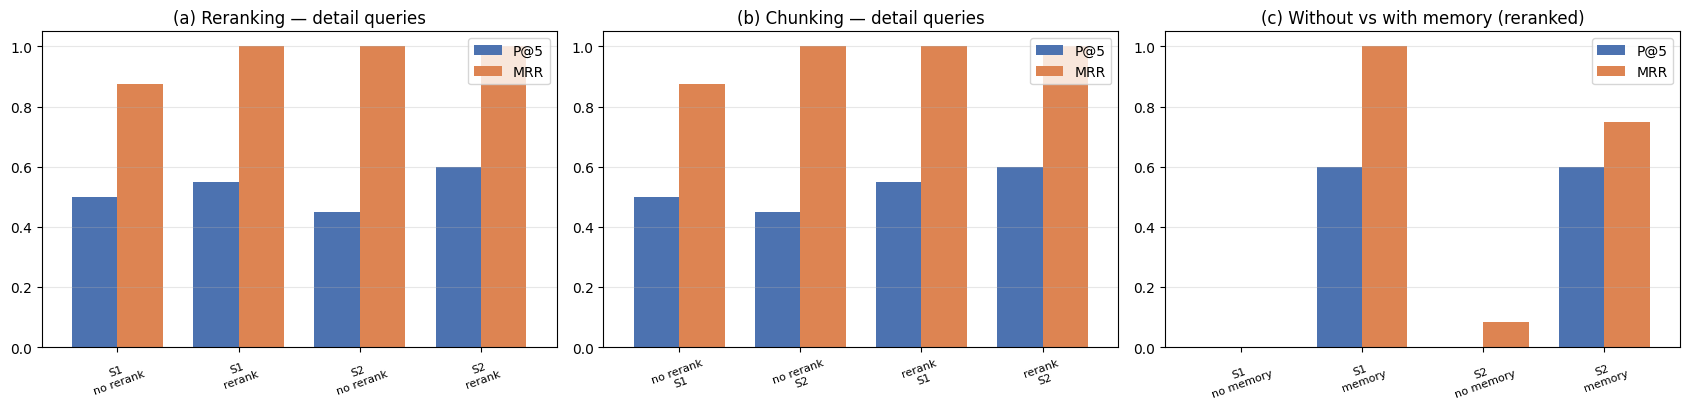

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
def bars(ax, df, title):
    df[[f"P@{K_MAIN}", "MRR"]].plot.bar(ax=ax, rot=20, width=0.75, color=["#4C72B0", "#DD8452"])
    ax.set_title(title); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=.3)
    ax.set_xticklabels([t.get_text().replace(" | ", "\n") for t in ax.get_xticklabels()], fontsize=8)
det = single_df[single_df.level == "detail"]
d_rr = det.groupby(["strategy", "rerank"])[METRICS].mean()
d_rr.index = [f"{s} | {label(r, 'rerank', 'no rerank')}" for s, r in d_rr.index]
d_ch = det.groupby(["rerank", "strategy"])[METRICS].mean()
d_ch.index = [f"{label(r, 'rerank', 'no rerank')} | {s}" for r, s in d_ch.index]
bars(axes[0], d_rr, "(a) Reranking — detail queries")
bars(axes[1], d_ch, "(b) Chunking — detail queries")
mem_rr = multi_df[multi_df.rerank].groupby(["strategy", "memory"])[METRICS].mean()
mem_rr.index = [f"{s} | {label(m, 'memory', 'no memory')}" for s, m in mem_rr.index]
bars(axes[2], mem_rr, "(c) Without vs with memory (reranked)")
plt.tight_layout(); plt.savefig("rag_comparison.png", dpi=150); plt.show()

In [16]:
# Auto-generated findings from the measured numbers (also saved to FINDINGS.md / METRICS.md / results CSVs)
def delta_line(name, before, after, metric):
    d = after - before
    verdict = "improved" if d > 0.005 else "hurt" if d < -0.005 else "did not change"
    return f"- {name}: {metric} {before:.3f} → {after:.3f} ({d:+.3f}, {verdict})"

lines = ["# Findings (auto-generated from this run)", "", f"K = {K_MAIN}; first-stage pool = {CANDIDATES}; "
         f"chunk budget = {CHUNK_WORDS} words", "", "## Without vs with reranking"]
for subset, df_ in [("all Q1–Q8", single_df), ("detail Q5–Q8", single_df[single_df.level == "detail"])]:
    for s in ["S1", "S2"]:
        g = df_[df_.strategy == s].groupby("rerank")[METRICS].mean()
        for m in [f"P@{K_MAIN}", "MRR"]:
            lines.append(delta_line(f"{STRATEGY_NAMES[s]} [{subset}]", g.loc[False, m], g.loc[True, m], m))
lines += ["", "## Chunking strategy 1 vs 2"]
for subset, df_ in [("all Q1–Q8", single_df), ("detail Q5–Q8", single_df[single_df.level == "detail"])]:
    for rr in [False, True]:
        g = df_[df_.rerank == rr].groupby("strategy")[METRICS].mean()
        for m in [f"P@{K_MAIN}", f"R@{max(KS)}", "MRR"]:
            lines.append(delta_line(f"S1→S2 ({label(rr, 'rerank', 'no rerank')}) [{subset}]", g.loc["S1", m], g.loc["S2", m], m))
lines += ["", "## Without vs with conversational memory (dependent turns)"]
for s in ["S1", "S2"]:
    for rr in [False, True]:
        g = multi_df[(multi_df.strategy == s) & (multi_df.rerank == rr)].groupby("memory")[METRICS].mean()
        for m in [f"P@{K_MAIN}", "MRR"]:
            lines.append(delta_line(f"{STRATEGY_NAMES[s]}, {label(rr, 'rerank', 'no rerank')}",
                                    g.loc[False, m], g.loc[True, m], m))
rank = single_df.groupby(["strategy", "rerank"])[["MRR", f"P@{K_MAIN}", f"R@{max(KS)}"]].mean()
rank = rank.sort_values(["MRR", f"P@{K_MAIN}", f"R@{max(KS)}"], ascending=False)
top = rank.iloc[0]; tied = rank[(rank == top).all(axis=1)].index.tolist()
names = [f"{STRATEGY_NAMES[s]} {label(r, 'with', 'without')} reranking" for s, r in tied]
lines += ["", ("**Best single-turn configuration** (MRR, then P@K, then R@10): " + names[0]) if len(names) == 1
          else ("**Tie for best single-turn configuration:** " + "; ".join(names))]
findings = "\n".join(lines)
print(findings)

open("FINDINGS.md", "w").write(findings)
single_df.round(4).to_csv("results_single_turn.csv", index=False)
multi_df.round(4).to_csv("results_multi_turn.csv", index=False)
with open("METRICS.md", "w") as f:
    f.write("# Metrics\n\n## (a) Reranking\n" + t_rerank.to_markdown() + "\n\n## (b) Chunking\n" + t_chunk.to_markdown()
            + "\n\n## (a+b) By query level\n" + t_level.to_markdown()
            + "\n\n## (c) Memory\n" + t_mem.to_markdown() + "\n")
print("\nSaved: FINDINGS.md, METRICS.md, results_single_turn.csv, results_multi_turn.csv, rag_comparison.png")

# Findings (auto-generated from this run)

K = 5; first-stage pool = 20; chunk budget = 120 words

## Without vs with reranking
- S1 fixed window [all Q1–Q8]: P@5 0.725 → 0.775 (+0.050, improved)
- S1 fixed window [all Q1–Q8]: MRR 0.938 → 1.000 (+0.062, improved)
- S2 sentence-aware [all Q1–Q8]: P@5 0.725 → 0.800 (+0.075, improved)
- S2 sentence-aware [all Q1–Q8]: MRR 1.000 → 1.000 (+0.000, did not change)
- S1 fixed window [detail Q5–Q8]: P@5 0.500 → 0.550 (+0.050, improved)
- S1 fixed window [detail Q5–Q8]: MRR 0.875 → 1.000 (+0.125, improved)
- S2 sentence-aware [detail Q5–Q8]: P@5 0.450 → 0.600 (+0.150, improved)
- S2 sentence-aware [detail Q5–Q8]: MRR 1.000 → 1.000 (+0.000, did not change)

## Chunking strategy 1 vs 2
- S1→S2 (no rerank) [all Q1–Q8]: P@5 0.725 → 0.725 (+0.000, did not change)
- S1→S2 (no rerank) [all Q1–Q8]: R@10 0.544 → 0.588 (+0.044, improved)
- S1→S2 (no rerank) [all Q1–Q8]: MRR 0.938 → 1.000 (+0.062, improved)
- S1→S2 (rerank) [all Q1–Q8]: P@5 0.775 → 0.800 (+

### Findings and discussion (from this run)

**Best configuration:** S2 sentence-aware chunking + cross-encoder reranking for single-turn queries, with conversational memory for follow-ups.

**1. Without vs with reranking — reranking helps, mainly on detail queries.**
Across Q1–Q8, P@5 rose from 0.725 → 0.775 (S1) and 0.725 → 0.800 (S2), and S1's MRR rose 0.938 → 1.000. On the detail queries (Q5–Q8), S2's P@5 went 0.45 → 0.60 and R@10 0.793 → 0.879; for Q6 and Q7 on S2, P@3 went 0.667 → 1.000. The topic queries (Q1–Q4) were already at P@5 0.95–1.00 for every method, so reranking had little to fix there. The bi-encoder ranks by overall topical similarity; the cross-encoder reads the query and chunk together, so it promotes the passage that states the specific finding over one that only shares the topic. It can only reorder the top-20 candidates, so it cannot recover a relevant chunk the first stage missed.

**2. Chunking strategy 1 vs 2 — sentence-aware chunking wins, most clearly with reranking.**
With reranking, S2 beats S1 on every metric overall (P@5 0.800 vs 0.775, R@10 0.638 vs 0.619) and on detail queries (P@5 0.60 vs 0.55, R@10 0.879 vs 0.793). Without reranking the picture is mixed: S2 has higher MRR (1.000 vs 0.938) and R@10 (0.588 vs 0.544) but the same P@5 overall and slightly lower P@5 on detail queries (0.45 vs 0.50). 98% of S2 chunks end on a sentence boundary versus 7% for S1, so S2 hands the embedder and reranker complete statements instead of claims cut mid-sentence; S2 chunks also exceed the 256-token embedder limit less often (5.7% vs 7.8%). Caveat: S2 produces more chunks (5,723 vs 5,164), so the number of relevant chunks per query differs between strategies, which affects Recall@K comparisons.

**3. Without vs with conversational memory — the largest effect in the study.**
The dependent turns ("…report for *it*", "…obtained *them* with") contain no topic words. Without memory they retrieved unrelated papers (for C1-T2: docs 90, 82, 40 — particle-physics fits, galaxy counts, document accessibility), giving P@5 = 0.0 in all four configurations and MRR ≤ 0.083. With memory, P@5 rose to 0.5–0.6 and MRR to 0.667–1.000. The strongest memory setting was S1 + reranking (P@5 0.6, MRR 1.0, R@10 0.597). S2 + reranking matched its P@5 (0.6) but had MRR 0.75: the concatenated query still carries the turn-1 wording, so a chunk that answers turn 1 rather than turn 2 can rank first. LLM-based query rewriting would remove that residue.

**Limitations.** 12 queries over 100 papers is a small sample, so single queries move the averages. Relevance comes from a hand-defined rubric (target paper + must-terms + answer terms) checked against the pooled review table, not exhaustive human judgment. Q8 has only 2 relevant chunks (flagged by the rubric check), which caps its P@5 at 0.4 for every method equally. The text is lowercased with equations removed, which weakens math-heavy passages, and 6–8% of chunks still slightly exceed the embedder's 256-token limit. Next steps: LLM query rewriting for memory, a larger reranker (`BAAI/bge-reranker-base`), and semantic chunking as a third strategy.


## 11. Improvements
The baseline left three weak spots: detail-query P@5 of only 0.45–0.60, a first stage that misses exact technical terms (*RKHS*, *linear trend*), and memory MRR of 0.67–0.75, because the concatenated query still carried turn-1 wording. Sections 1–10 are unchanged; this section adds:

| # | Improvement | Targets |
|---|---|---|
| I1 | **Hybrid first stage:** BM25 + dense, fused with Reciprocal Rank Fusion (RRF) | Exact-term matches the bi-encoder misses |
| I2 | **Stronger reranker:** `BAAI/bge-reranker-base` (278M) over a 40-candidate pool, vs MiniLM-L6 (22M) over 20 | Detail-query precision |
| I3 | **Anchored memory:** (a) only rewrites real follow-ups (pronouns or ≤2 content words), (b) adds turn-1 *keywords* instead of the whole sentence, (c) restricts retrieval to the paper the conversation is about when the previous turn's top-5 agree on it | Turn-1 leftovers, topic switches |

A third conversation, **C3 (topic switch)**, tests whether memory *hurts* when the second question is unrelated to the first. The baseline concatenation memory has no way to tell.

In [17]:
!pip -q install rank_bm25

In [18]:
from collections import Counter
from rank_bm25 import BM25Okapi

STOP = set('''a an the of for to in on and or is are was were be been by with as at from that this these those it its
they them their what which how why can do does did we our you your into than then there here also not no such
which who whom when where while about over under between'''.split())
def tokenize(t):
    return [w for w in re.findall(r"[a-z0-9][a-z0-9\-]*", t.lower()) if w not in STOP and len(w) > 1]

BM25    = {s: BM25Okapi([tokenize(c["text"]) for c in CHUNKS[s]]) for s in CHUNKS}
DOC_IDX = {s: np.array([c["doc_id"] for c in CHUNKS[s]]) for s in CHUNKS}

def _fmt(c, **score):
    return {"id": c["id"], "text": c["text"], "doc_id": int(c["doc_id"]), **score}

def bm25_search(strategy, query, n, scope=None):
    scores = BM25[strategy].get_scores(tokenize(query))
    if scope is not None:
        scores = np.where(np.isin(DOC_IDX[strategy], scope), scores, -np.inf)
    top = np.argsort(-scores)[:n]
    return [_fmt(CHUNKS[strategy][i], bm25_score=float(scores[i])) for i in top if np.isfinite(scores[i])]

def dense_search_v2(strategy, query, n, scope=None):
    kw = {}
    if scope is not None:                                   # metadata filter inside ChromaDB
        n = min(n, int(np.isin(DOC_IDX[strategy], scope).sum()))
        kw["where"] = {"doc_id": {"$in": [int(d) for d in scope]}}
    q = embedder.encode([query], normalize_embeddings=True).tolist()
    r = COLS[strategy].query(query_embeddings=q, n_results=n, include=["documents", "metadatas", "distances"], **kw)
    return [{"id": i, "text": t, "doc_id": int(m["doc_id"]), "dense_score": round(1 - d, 4)}
            for i, t, m, d in zip(r["ids"][0], r["documents"][0], r["metadatas"][0], r["distances"][0])]

def hybrid_search(strategy, query, n, scope=None, depth=50, k_rrf=60):
    # Reciprocal Rank Fusion: score = sum over lists of 1 / (k_rrf + rank)
    fused, info = defaultdict(float), {}
    for lst in (dense_search_v2(strategy, query, depth, scope), bm25_search(strategy, query, depth, scope)):
        for rank, c in enumerate(lst, 1):
            fused[c["id"]] += 1.0 / (k_rrf + rank); info[c["id"]] = c
    ids = sorted(fused, key=lambda i: -fused[i])[:n]
    return [_fmt(info[i], rrf_score=round(fused[i], 5)) for i in ids]

# Verification: unscoped dense_search_v2 matches the baseline; BM25 finds the target paper for an exact-term query
for s in CHUNKS:
    a = [c["id"] for c in dense_search(s, QUERIES["Q5"]["text"], 10)]
    b = [c["id"] for c in dense_search_v2(s, QUERIES["Q5"]["text"], 10)]
    assert a == b, "dense_search_v2 differs from baseline"
    top_bm25 = bm25_search(s, "rkhs gaussian rbf kernel additive", 5)
    print(f"{s}: dense_v2 == baseline OK | BM25 top-5 docs for 'rkhs gaussian rbf kernel additive': {[c['doc_id'] for c in top_bm25]}")

S1: dense_v2 == baseline OK | BM25 top-5 docs for 'rkhs gaussian rbf kernel additive': [0, 0, 0, 0, 0]
S2: dense_v2 == baseline OK | BM25 top-5 docs for 'rkhs gaussian rbf kernel additive': [0, 0, 0, 0, 0]


In [19]:
RERANKERS = {"minilm": reranker,
             "bge": CrossEncoder("BAAI/bge-reranker-base", device=DEVICE, max_length=512)}

def retrieve_v2(strategy, query, k=max(KS), first="dense", rr=None, pool=20, scope=None, rr_query=None):
    cands = (hybrid_search if first == "hybrid" else dense_search_v2)(strategy, query, pool, scope)
    if rr:
        scores = RERANKERS[rr].predict([(rr_query or query, c["text"]) for c in cands], batch_size=32)
        cands = sorted([{**c, "rerank_score": float(s)} for c, s in zip(cands, scores)], key=lambda c: -c["rerank_score"])
    return cands[:k]

PIPES = {
    "Dense":                 dict(first="dense",  rr=None,     pool=20),
    "Dense + MiniLM (base)": dict(first="dense",  rr="minilm", pool=20),
    "Hybrid":                dict(first="hybrid", rr=None,     pool=20),
    "Hybrid + MiniLM":       dict(first="hybrid", rr="minilm", pool=20),
    "Hybrid + BGE (pool 40)":dict(first="hybrid", rr="bge",    pool=40),
}

# Verification: the baseline pipeline reproduces Section 9's numbers
chk = [score_row(q, "S2", retrieve_v2("S2", v["text"], **PIPES["Dense + MiniLM (base)"]))["MRR"] for q, v in QUERIES.items()]
ref = single_df[(single_df.strategy == "S2") & single_df.rerank]["MRR"].tolist()
print("Baseline reproduced:", np.allclose(chk, ref))

config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Baseline reproduced: True


### I1 + I2: single-turn results

In [20]:
rows = []
for s in ["S1", "S2"]:
    for pname, cfg in PIPES.items():
        for qid, q in QUERIES.items():
            rows.append(score_row(qid, s, retrieve_v2(s, q["text"], **cfg), pipeline=pname, level=LEVEL[qid]))
imp_single = pd.DataFrame(rows)

order = list(PIPES)
def summarize(df):
    t = df.groupby(["strategy", "pipeline"])[METRICS].mean().round(3).reset_index()
    t["pipeline"] = pd.Categorical(t["pipeline"], order, ordered=True)
    return t.sort_values(["strategy", "pipeline"]).set_index(["strategy", "pipeline"])
print("All queries (Q1–Q8)");     display(summarize(imp_single))
print("Detail queries (Q5–Q8)");  display(summarize(imp_single[imp_single.level == "detail"]))

All queries (Q1–Q8)


P@5    R@5   R@10    MRR
strategy pipeline                                          
S1       Dense                   0.725  0.433  0.544  0.938
         Dense + MiniLM (base)   0.775  0.483  0.619  1.000
         Hybrid                  0.725  0.423  0.644  0.875
         Hybrid + MiniLM         0.800  0.508  0.638  1.000
         Hybrid + BGE (pool 40)  0.650  0.416  0.628  0.875
S2       Dense                   0.725  0.385  0.588  1.000
         Dense + MiniLM (base)   0.800  0.453  0.638  1.000
         Hybrid                  0.775  0.428  0.638  1.000
         Hybrid + MiniLM         0.800  0.453  0.631  1.000
         Hybrid + BGE (pool 40)  0.800  0.457  0.631  1.000

Detail queries (Q5–Q8)


P@5    R@5   R@10    MRR
strategy pipeline                                         
S1       Dense                   0.50  0.660  0.660  0.875
         Dense + MiniLM (base)   0.55  0.743  0.793  1.000
         Hybrid                  0.45  0.624  0.843  0.750
         Hybrid + MiniLM         0.60  0.793  0.864  1.000
         Hybrid + BGE (pool 40)  0.50  0.660  0.879  0.875
S2       Dense                   0.45  0.571  0.793  1.000
         Dense + MiniLM (base)   0.60  0.707  0.879  1.000
         Hybrid                  0.55  0.657  0.893  1.000
         Hybrid + MiniLM         0.60  0.707  0.879  1.000
         Hybrid + BGE (pool 40)  0.65  0.729  0.879  1.000

In [21]:
# Side-by-side example: detail query Q5 on S2, baseline vs best pipeline
q = QUERIES["Q5"]
for pname in ["Dense + MiniLM (base)", "Hybrid + BGE (pool 40)"]:
    print(f"\n--- {pname} | {q['text']}")
    for r, c in enumerate(retrieve_v2("S2", q["text"], k=5, **PIPES[pname]), 1):
        print(f"{r}. [doc {c['doc_id']:>2} | relevant={is_relevant('Q5', c)}] {c['text'][:140]}...")


--- Dense + MiniLM (base) | Can a Gaussian function of a single variable belong to the RKHS of a multivariate Gaussian RBF kernel?
1. [doc  0 | relevant=1] all proofs will be given in section [proofsection]. [gaussadd] let, $] and ^ 2.$] let and.\]] the additive kernel is given by furthermore, t...
2. [doc  0 | relevant=1] because these notations will only be used in different places and because we do not expect any misunderstandings, we think this notation is ...
3. [doc  0 | relevant=0] it is an rkhs with a mercer kernel defined on ^ 2 $]. if we take all the mercer kernels to be, then $] for each. the additive kernel is also...
4. [doc  0 | relevant=1] [capacitythm] under assumption [assumption2], for any and, we have the bound for the covering numbers stated in theorem [capacitythm] is spe...
5. [doc  0 | relevant=0] note that the kernel in the above example is independent of the sample size. it would be interesting to see whether there exists some such t...

--- Hybrid + BGE (pool

### I3: anchored conversational memory

In [22]:
ANAPHORA = {"it", "its", "they", "them", "their", "theirs", "these", "those", "he", "she", "his", "her"}

class AnchoredMemory:
    # Follow-up detection -> keyword rewrite -> paper-scoped retrieval (only when the last turn is confident)
    def __init__(self, window=2, min_agree=3):
        self.window, self.min_agree, self.turns = window, min_agree, []

    def is_followup(self, query):
        words = set(re.findall(r"[a-z]+", query.lower()))
        return bool(self.turns) and (bool(words & ANAPHORA) or len(tokenize(query)) <= 2)

    def topic_terms(self):
        terms = []
        for t in self.turns[-self.window:]:
            terms += [w for w in tokenize(t["query"]) if w not in terms]
        return terms

    def scope(self):
        doc, cnt = Counter(self.turns[-1]["top_docs"]).most_common(1)[0]
        return [doc] if cnt >= self.min_agree else None        # don't lock in an uncertain paper

    def prepare(self, query):
        if not self.is_followup(query):
            return query, None, False                           # new topic: send as-is
        own = set(tokenize(query))
        rewritten = " ".join(w for w in self.topic_terms() if w not in own) + " " + query
        return rewritten, self.scope(), True

    def add(self, query, results):
        self.turns.append({"query": query, "top_docs": [r["doc_id"] for r in results[:5]]})

# C3: topic switch — turn 2 is unrelated to turn 1 and should NOT be rewritten
CONV_V2 = dict(CONVERSATIONS)
CONV_V2["C3"] = [dict(qid="C3-T1", **QUERIES["Q2"]), dict(qid="C3-T2", **QUERIES["Q3"])]
ALL_Q.update({t["qid"]: t for t in CONV_V2["C3"]})

def run_conv_v2(strategy, turns, mode, pipe):
    v1, v2, log = ConversationMemory(window=2), AnchoredMemory(), []
    for t in turns:
        q, scope, fu = t["text"], None, False
        if mode == "concat":
            q = v1.contextualize(t["text"])
        elif mode == "anchored":
            q, scope, fu = v2.prepare(t["text"])
        res = retrieve_v2(strategy, q, scope=scope, rr_query=q, **pipe)
        v1.add(t["text"], q, res); v2.add(t["text"], res)
        log.append({"qid": t["qid"], "sent_query": q, "scope": scope, "followup": fu, "results": res})
    return log

# Verification: follow-up detection fires on C1/C2 turn 2 and not on the C3 topic switch
for cid, turns in CONV_V2.items():
    t2 = run_conv_v2("S2", turns, "anchored", PIPES["Hybrid + BGE (pool 40)"])[1]
    print(f"{cid}-T2 follow-up={t2['followup']!s:5} scope={t2['scope']} | sent: {t2['sent_query'][:110]!r}")
    assert t2["followup"] == (cid != "C3")

C1-T2 follow-up=True  scope=[3] | sent: 'random phase diffuser reduce scintillations laser light What results do the authors report for it, and how doe'
C2-T2 follow-up=True  scope=[9] | sent: 'long-term radial velocity measurements reveal additional planets Which instruments and observations were they '
C3-T2 follow-up=False scope=None | sent: 'How is synaptic memory modeled as the basis of learning?'


In [23]:
# Demo: C1 with anchored memory (best pipeline, S2)
for turn in run_conv_v2("S2", CONV_V2["C1"], "anchored", PIPES["Hybrid + BGE (pool 40)"]):
    print(f"\n[{turn['qid']}] scope={turn['scope']} | query: {turn['sent_query']!r}")
    for r, c in enumerate(turn["results"][:3], 1):
        print(f"  {r}. [doc {c['doc_id']:>2} | relevant={is_relevant(turn['qid'], c)}] {c['text'][:130]}...")


[C1-T1] scope=None | query: 'How does a random phase diffuser reduce scintillations of laser light?'
  1. [doc  3 | relevant=1] it is given by }+ e^{-\lambda _ c^{-2}[({\bf r-r^\prime}_1)^2+({\bf r^\prime -r_1})^2]-2\nu^2\tau ^2},\]] where ^ 2\rangle = 2\nu^...
  2. [doc  3 | relevant=1] [two] that the functional, is quadratic in the distribution function,. hence, four-wave correlations determine the value of scinti...
  3. [doc  3 | relevant=1] the coherent laser beam can be transformed into a partially coherent beam by means of a phase diffuser placed near the exit apertu...

[C1-T2] scope=[3] | query: 'random phase diffuser reduce scintillations laser light What results do the authors report for it, and how does it compare to the case without it?'
  1. [doc  3 | relevant=0] it is given by }+ e^{-\lambda _ c^{-2}[({\bf r-r^\prime}_1)^2+({\bf r^\prime -r_1})^2]-2\nu^2\tau ^2},\]] where ^ 2\rangle = 2\nu^...
  2. [doc  3 | relevant=1] moreover, comparing the two upper curves in fig. 3

In [24]:
MEM_PIPES = ["Dense + MiniLM (base)", "Hybrid + BGE (pool 40)"]
rows = []
for s in ["S1", "S2"]:
    for pname in MEM_PIPES:
        for mode in ["none", "concat", "anchored"]:
            for cid, turns in CONV_V2.items():
                t2 = run_conv_v2(s, turns, mode, PIPES[pname])[1]
                rows.append(score_row(t2["qid"], s, t2["results"], pipeline=pname, memory=mode,
                                      conv_type="topic switch" if cid == "C3" else "dependent"))
imp_multi = pd.DataFrame(rows)
mem_order = {"none": 0, "concat": 1, "anchored": 2}
for ctype in ["dependent", "topic switch"]:
    t = (imp_multi[imp_multi.conv_type == ctype].groupby(["strategy", "pipeline", "memory"])[METRICS]
         .mean().round(3).reset_index())
    t = t.sort_values(["strategy", "pipeline", "memory"], key=lambda c: c.map(mem_order) if c.name == "memory" else c)
    print(f"Memory — {ctype} turns ({'C1-T2, C2-T2' if ctype == 'dependent' else 'C3-T2'})")
    display(t.set_index(["strategy", "pipeline", "memory"]))

Memory — dependent turns (C1-T2, C2-T2)


P@5    R@5   R@10    MRR
strategy pipeline               memory                            
S1       Dense + MiniLM (base)  none      0.0  0.000  0.000  0.000
                                concat    0.6  0.306  0.597  1.000
                                anchored  0.7  0.347  0.639  1.000
         Hybrid + BGE (pool 40) none      0.1  0.042  0.042  0.100
                                concat    0.6  0.292  0.444  0.750
                                anchored  0.7  0.347  0.486  1.000
S2       Dense + MiniLM (base)  none      0.0  0.000  0.045  0.083
                                concat    0.6  0.325  0.558  0.750
                                anchored  0.6  0.325  0.558  1.000
         Hybrid + BGE (pool 40) none      0.0  0.000  0.045  0.050
                                concat    0.3  0.188  0.468  0.375
                                anchored  0.5  0.279  0.513  0.750

Memory — topic switch turns (C3-T2)


P@5    R@5   R@10    MRR
strategy pipeline               memory                            
S1       Dense + MiniLM (base)  none      1.0  0.333  0.667  1.000
                                concat    0.0  0.000  0.067  0.125
                                anchored  1.0  0.333  0.667  1.000
         Hybrid + BGE (pool 40) none      0.6  0.200  0.533  0.500
                                concat    0.0  0.000  0.000  0.000
                                anchored  0.6  0.200  0.533  0.500
S2       Dense + MiniLM (base)  none      1.0  0.278  0.556  1.000
                                concat    0.0  0.000  0.056  0.100
                                anchored  1.0  0.278  0.556  1.000
         Hybrid + BGE (pool 40) none      0.8  0.222  0.500  1.000
                                concat    0.0  0.000  0.056  0.167
                                anchored  0.8  0.222  0.500  1.000

### Improvement summary

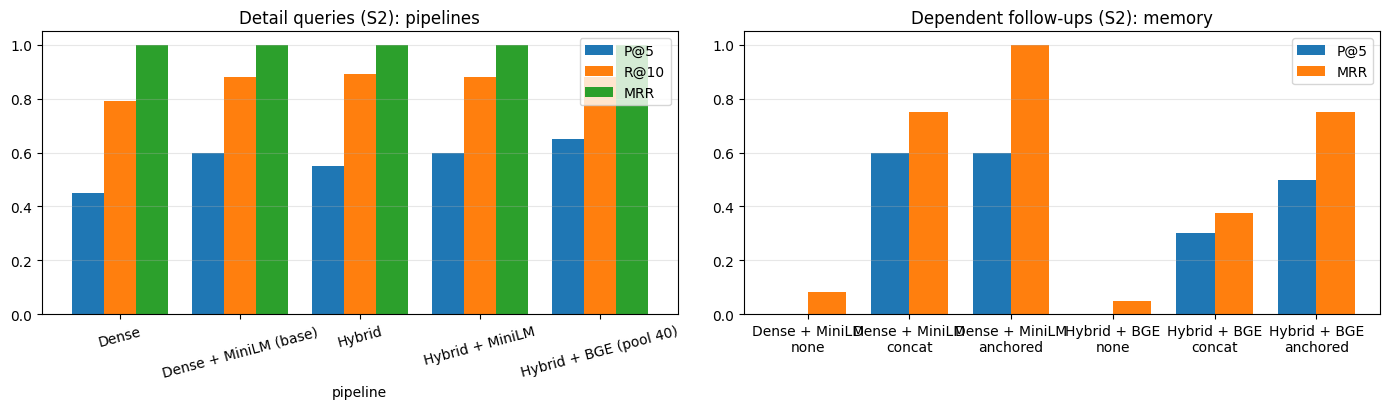

# Improvements (auto-generated from this run)

## Single-turn detail queries (Q5–Q8)
- S1 fixed window: baseline → Hybrid + BGE: P@5 0.550 → 0.500 (-0.050, hurt)
- S1 fixed window: baseline → Hybrid + BGE: R@10 0.793 → 0.879 (+0.086, improved)
- S1 fixed window: baseline → Hybrid + BGE: MRR 1.000 → 0.875 (-0.125, hurt)
- S2 sentence-aware: baseline → Hybrid + BGE: P@5 0.600 → 0.650 (+0.050, improved)
- S2 sentence-aware: baseline → Hybrid + BGE: R@10 0.879 → 0.879 (+0.000, did not change)
- S2 sentence-aware: baseline → Hybrid + BGE: MRR 1.000 → 1.000 (+0.000, did not change)

## Dependent follow-ups (C1-T2, C2-T2), Hybrid + BGE
- S1 fixed window: concat memory → anchored memory: P@5 0.600 → 0.700 (+0.100, improved)
- S1 fixed window: concat memory → anchored memory: MRR 0.750 → 1.000 (+0.250, improved)
- S2 sentence-aware: concat memory → anchored memory: P@5 0.300 → 0.500 (+0.200, improved)
- S2 sentence-aware: concat memory → anchored memory: MRR 0.375 → 0.750 (+0.375, improved)

##

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
det = summarize(imp_single[imp_single.level == "detail"]).loc["S2"]
det[[f"P@{K_MAIN}", f"R@{max(KS)}", "MRR"]].plot.bar(ax=axes[0], rot=15, width=0.8)
axes[0].set_title("Detail queries (S2): pipelines"); axes[0].set_ylim(0, 1.05); axes[0].grid(axis="y", alpha=.3)
dep = (imp_multi[(imp_multi.conv_type == "dependent") & (imp_multi.strategy == "S2")]
       .groupby(["pipeline", "memory"])[[f"P@{K_MAIN}", "MRR"]].mean())
dep = dep.reindex(sorted(dep.index, key=lambda i: (MEM_PIPES.index(i[0]), mem_order[i[1]])))
dep.index = [f"{p.split(' (')[0]}\n{m}" for p, m in dep.index]
dep.plot.bar(ax=axes[1], rot=0, width=0.75)
axes[1].set_title("Dependent follow-ups (S2): memory"); axes[1].set_ylim(0, 1.05); axes[1].grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig("rag_improvements.png", dpi=150); plt.show()

def mean(df, **f):
    for k, v in f.items(): df = df[df[k] == v]
    return df[METRICS].mean()

L = ["# Improvements (auto-generated from this run)", "", "## Single-turn detail queries (Q5–Q8)"]
for s in ["S1", "S2"]:
    d = imp_single[imp_single.level == "detail"]
    b, best = mean(d, strategy=s, pipeline="Dense + MiniLM (base)"), mean(d, strategy=s, pipeline="Hybrid + BGE (pool 40)")
    for m in [f"P@{K_MAIN}", f"R@{max(KS)}", "MRR"]:
        L.append(delta_line(f"{STRATEGY_NAMES[s]}: baseline → Hybrid + BGE", b[m], best[m], m))
L += ["", "## Dependent follow-ups (C1-T2, C2-T2), Hybrid + BGE"]
for s in ["S1", "S2"]:
    d = imp_multi[(imp_multi.conv_type == "dependent") & (imp_multi.pipeline == "Hybrid + BGE (pool 40)")]
    c, a = mean(d, strategy=s, memory="concat"), mean(d, strategy=s, memory="anchored")
    for m in [f"P@{K_MAIN}", "MRR"]:
        L.append(delta_line(f"{STRATEGY_NAMES[s]}: concat memory → anchored memory", c[m], a[m], m))
L += ["", "## Topic switch (C3-T2), Hybrid + BGE"]
for s in ["S1", "S2"]:
    d = imp_multi[(imp_multi.conv_type == "topic switch") & (imp_multi.pipeline == "Hybrid + BGE (pool 40)")]
    for mode in ["none", "concat", "anchored"]:
        r = mean(d, strategy=s, memory=mode)
        L.append(f"- {STRATEGY_NAMES[s]}, memory={mode}: P@{K_MAIN} {r[f'P@{K_MAIN}']:.3f}, MRR {r['MRR']:.3f}")

rank = (imp_single[imp_single.level == "detail"].groupby(["strategy", "pipeline"])[["MRR", f"P@{K_MAIN}", f"R@{max(KS)}"]]
        .mean().sort_values(["MRR", f"P@{K_MAIN}", f"R@{max(KS)}"], ascending=False))
L += ["", f"**Best on detail queries:** {STRATEGY_NAMES[rank.index[0][0]]} + {rank.index[0][1]} "
          f"(MRR {rank.iloc[0]['MRR']:.3f}, P@{K_MAIN} {rank.iloc[0][f'P@{K_MAIN}']:.3f}, R@10 {rank.iloc[0][f'R@{max(KS)}']:.3f})"]
improvements = "\n".join(L); print(improvements)
open("IMPROVEMENTS.md", "w").write(improvements)
imp_single.round(4).to_csv("improved_single_turn.csv", index=False)
imp_multi.round(4).to_csv("improved_multi_turn.csv", index=False)
print("\nSaved: IMPROVEMENTS.md, improved_single_turn.csv, improved_multi_turn.csv, rag_improvements.png")

### Why each improvement should help (check against the summary above)
* **Hybrid BM25 + dense (I1).** MiniLM squeezes a chunk into one 384-d vector, so rare exact terms such as *RKHS*, *linear trend* or *detector* get diluted. BM25 scores those terms directly. RRF merges the two rankings without needing their scores on a common scale, so the candidate pool contains chunks found by either method.
* **BGE reranker, pool 40 (I2).** A cross-encoder can only reorder what the first stage gives it. A deeper pool raises the recall ceiling, and the larger BGE model separates "states the finding" from "mentions the topic" better than MiniLM-L6.
* **Anchored memory (I3).** Concatenating the whole turn-1 sentence pulls back chunks that answered turn 1. Adding only turn-1 *keywords* resolves the pronoun with less leftover wording. Scoping to the paper the last turn agreed on removes off-topic papers entirely. The follow-up check leaves unrelated questions alone: on C3, concatenation mixes the diffuser topic into a synaptic-memory question, while anchored memory sends it unchanged.
* **Trade-offs.** Hybrid + BGE costs about 3–5× the latency of dense + MiniLM per query. Paper scoping depends on turn 1 being right, which is why it applies only when ≥3 of the previous top-5 chunks agree. The rubric is unchanged from Sections 6–9, so every number is directly comparable to the baseline.